# Лабораторная работа 1. Часть на C++

Ноутбук собирает и запускает программу на C++ из папки `cpp/` (`main.cpp`, `CMakeLists.txt`) и сравнивает её
с Python на тех же моделях и том же видео.

| Раздел | Что делается |
|---|---|
| 0 | Настройки и проверка инструментов (CMake, компилятор, OpenCV, ONNX Runtime) |
| 1 | Устройство программы `yolo_video` |
| 2 | Сборка через CMake |
| 3 | Запуск: OpenCV DNN и ONNX Runtime — FP32, INT8, модели со сжатием кадра внутри (interpolate и свёртка), GPU при наличии |
| 4 | Сравнение с Python по этапам конвейера |
| 5 | Кадры видео, размеченного программой на C++ |

**Порядок:** сначала выполните `lab1_yolo.ipynb` — он создаёт модели в `models/` и видео `data/demo.mp4`.
Затем **Run All** здесь.

**Нужно установить:** CMake ≥ 3.18, компилятор C++17, OpenCV ≥ 4.10 для C++ (Windows — релиз с opencv.org,
macOS — `brew install opencv`, Linux — сборка из исходников: в Ubuntu 24.04 apt даёт 4.6, она не открывает YOLO26).
Для бэкенда ONNX Runtime (INT8, сжатие внутри модели, CUDA/TensorRT) — распакованный релиз ONNX Runtime
с github.com/microsoft/onnxruntime/releases. Подробнее — `cpp/README.md`.

## 0. Настройки и проверка инструментов

Пути можно задать здесь или переменными окружения до запуска Jupyter (`OpenCV_DIR`, `ONNXRUNTIME_DIR`).
`None` — CMake ищет OpenCV сам (brew, системная установка); без ONNX Runtime соберётся только бэкенд OpenCV.

In [1]:
import os

OPENCV_DIR = os.environ.get("OpenCV_DIR")            # папка с OpenCVConfig.cmake, например C:/opencv/build
ONNXRUNTIME_DIR = os.environ.get("ONNXRUNTIME_DIR")  # распакованный релиз ONNX Runtime (папки include/ и lib/)
STEM = "yolo26n"                                     # модель из lab1_yolo.ipynb
VIDEO = "data/demo.mp4"
MAX_FRAMES = 150                                     # кадров на каждый запуск
REPEATS = 2                                          # прогонов на конфигурацию; берётся лучший (меньше влияние фоновой нагрузки)

In [2]:
import ast
import platform
import re
import shutil
import subprocess
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
from IPython.display import Markdown, display

ROOT = Path.cwd()
CPP, BUILD, MODELS, RUNS = ROOT / "cpp", ROOT / "cpp" / "build", ROOT / "models", ROOT / "runs" / "cpp"
RUNS.mkdir(parents=True, exist_ok=True)
WIN = platform.system() == "Windows"


def sh(cmd, cwd=None):
    # Запустить команду и вернуть (код, вывод); вывод — UTF-8 (так пишет программа на C++)
    p = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True, encoding="utf-8", errors="replace")
    return p.returncode, (p.stdout or "") + (p.stderr or "")


def first_line(cmd):
    try:
        return sh(cmd)[1].strip().splitlines()[0]
    except Exception as e:
        return f"не найден ({type(e).__name__})"


print("ОС:        ", platform.system(), platform.machine())
print("CMake:     ", first_line(["cmake", "--version"]))
print("Компилятор:", "MSVC (Visual Studio)" if WIN else first_line(["c++", "--version"]))
print("OpenCV_DIR:", OPENCV_DIR or "не задан — CMake ищет сам")
print("ONNX Runtime:", ONNXRUNTIME_DIR or "не задан — только бэкенд OpenCV")
GPU = shutil.which("nvidia-smi") is not None
print("NVIDIA GPU:", first_line(["nvidia-smi", "-L"]) if GPU else "нет")

need = [MODELS / f"{STEM}.onnx", MODELS / f"{STEM}_int8.onnx", ROOT / VIDEO]
missing = [str(p.relative_to(ROOT)) for p in need if not p.exists()]
if missing:
    raise FileNotFoundError(f"Нет файлов {missing} — сначала выполните lab1_yolo.ipynb (Run All)")
COMPRESSED = sorted(MODELS.glob(f"{STEM}_compressed_*_to_320.onnx"))
print("\nМодели:", ", ".join(p.name for p in need[:2] + COMPRESSED))

ОС:         Linux x86_64
CMake:      cmake version 3.28.3
Компилятор: c++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
OpenCV_DIR: /opt/opencv-4.14/lib/cmake/opencv4
ONNX Runtime: /opt/onnxruntime-linux-x64-1.32.0
NVIDIA GPU: нет

Модели: yolo26n.onnx, yolo26n_int8.onnx, yolo26n_compressed_conv_1280x720_to_320.onnx, yolo26n_compressed_interpolate_1280x720_to_320.onnx


## 1. Устройство программы

`cpp/main.cpp` повторяет конвейер Python: чтение кадра → подготовка входа → инференс → разбор выхода YOLO и NMS →
отрисовка и запись видео, с замером времени каждого этапа.

| Часть | Что делает |
|---|---|
| `make_blob` | letterbox: масштаб с сохранением пропорций, серые поля до 640×640, RGB, /255, NCHW |
| `postprocess` | выход `(1, 4+nc, N)` → порог и NMS по классам; выход `(1, N, 6)` (NMS-free) → сразу рамки |
| `OpenCVBackend` | `cv::dnn` — CPU; `cuda`/`cuda-fp16` для OpenCV 4.x, собранного с CUDA |
| `OrtBackend` | ONNX Runtime — CPU, CUDA, TensorRT, CoreML, OpenVINO; понимает модели с входом uint8 [1,H,W,3]: кадр передаётся **без препроцессинга** — сжатие делает сама модель (раздел 3 `lab1_yolo.ipynb`) |

In [3]:
src = (CPP / "main.cpp").read_text(encoding="utf-8")
print(f"main.cpp: {len(src.splitlines())} строк")
for m in re.finditer(r"^(class \w+[^{]*|static [\w:<>]+ \w+\(|int main\()", src, re.M):
    print("  ", m.group(1).strip().rstrip("("))

main.cpp: 423 строк
   static void usage
   static Args parse
   static cv::Mat make_blob
   static std::vector<Detection> postprocess
   static void draw
   class Backend
   class OpenCVBackend : public Backend
   class OrtBackend : public Backend
   static double ms_since
   int main


## 2. Сборка

`cmake -S cpp -B cpp/build` + `cmake --build`. С `-DWITH_ORT=ON` добавляется бэкенд ONNX Runtime.

In [4]:
cfg = ["cmake", "-S", str(CPP), "-B", str(BUILD), "-DCMAKE_BUILD_TYPE=Release"]
if OPENCV_DIR:
    cfg.append(f"-DOpenCV_DIR={OPENCV_DIR}")
if ONNXRUNTIME_DIR:
    cfg += ["-DWITH_ORT=ON", f"-DONNXRUNTIME_DIR={ONNXRUNTIME_DIR}"]
t0 = time.perf_counter()
code_cfg, out_cfg = sh(cfg)
print("\n".join(l for l in out_cfg.splitlines() if "OpenCV" in l or "ONNX" in l or "Error" in l or "error" in l))
if code_cfg:
    print(out_cfg[-3000:])
    raise RuntimeError("CMake не сконфигурировал проект — проверьте OpenCV_DIR (cpp/README.md)")
code_b, out_b = sh(["cmake", "--build", str(BUILD), "--config", "Release", "-j"])
print("\n".join(out_b.strip().splitlines()[-3:]))
if code_b:
    print(out_b[-3000:])
    raise RuntimeError("Сборка не удалась")
EXE = next(p for p in [BUILD / "yolo_video", BUILD / "Release" / "yolo_video.exe", BUILD / "yolo_video.exe"] if p.exists())
WITH_ORT = bool(ONNXRUNTIME_DIR)
print(f"\nГотово за {time.perf_counter() - t0:.0f} с: {EXE.relative_to(ROOT)}  (ONNX Runtime: {WITH_ORT})")

-- Found OpenCV: /opt/opencv-4.14 (found version "4.14.0") found components: core imgproc imgcodecs videoio highgui dnn 
-- OpenCV 4.14.0
-- ONNX Runtime: /opt/onnxruntime-linux-x64-1.32.0/lib/libonnxruntime.so


[ 50%] Building CXX object CMakeFiles/yolo_video.dir/main.cpp.o
[100%] Linking CXX executable yolo_video
[100%] Built target yolo_video

Готово за 3 с: cpp/build/yolo_video  (ONNX Runtime: True)


## 3. Запуск программы на C++

Каждая конфигурация обрабатывает одни и те же кадры видео (`REPEATS` прогонов, берётся лучший); вывод программы
разбирается в таблицу.
Варианты с GPU добавляются, только если есть NVIDIA GPU (а для ORT — GPU-сборка ONNX Runtime).

In [5]:
def run_cpp(model, backend="opencv", device="cpu", tag=None):
    out = RUNS / f"{tag or Path(model).stem}_{backend}_{device}.mp4"
    cmd = [str(EXE), str(MODELS / model), str(ROOT / VIDEO), "--backend", backend, "--device", device,
           "--max-frames", str(MAX_FRAMES), "--out", str(out)]
    code, text = sh(cmd, cwd=CPP)
    if code:
        raise RuntimeError(text.strip().splitlines()[-1])
    num = lambda key: float(re.search(rf"{key}\s+([\d.]+)", text).group(1))
    return {"backend_name": re.search(r"Бэкенд:\s+(.+)", text).group(1).strip(),
            "warn": [l.strip() for l in text.splitlines() if l.startswith("[!]")],
            "read": num("read"), "pre": num("preprocess"), "inf": num("inference"), "post": num("postprocess"),
            "draw": num("draw\\+write"), "fps_model": float(re.search(r"FPS модели[^:]*:\s+([\d.]+)", text).group(1)),
            "fps_pipe": float(re.search(r"FPS всего конвейера:\s+([\d.]+)", text).group(1)), "video": out}


ort_libs = list(Path(ONNXRUNTIME_DIR or ".").glob("lib/*providers_cuda*"))
configs = [("FP32", f"{STEM}.onnx", "opencv", "cpu")]
if GPU:
    configs.append(("FP32", f"{STEM}.onnx", "opencv", "cuda-fp16"))
if WITH_ORT:
    configs += [("FP32", f"{STEM}.onnx", "ort", "cpu"), ("INT8", f"{STEM}_int8.onnx", "ort", "cpu")]
    configs += [(f"сжатие до 320: {p.stem.split('_')[2]}", p.name, "ort", "cpu") for p in COMPRESSED]
    if GPU and ort_libs:
        configs += [("FP32", f"{STEM}.onnx", "ort", "cuda"), ("FP16", f"{STEM}_fp16.onnx", "ort", "trt"),
                    ("INT8", f"{STEM}_int8.onnx", "ort", "trt")]
    if platform.system() == "Darwin":
        configs.append(("FP32", f"{STEM}.onnx", "ort", "coreml"))

cpp_res = {}
for label, model, backend, device in configs:
    try:
        r = min((run_cpp(model, backend, device) for _ in range(REPEATS)), key=lambda d: d["inf"])
    except Exception as e:
        print(f"{label} {backend} {device}: пропущено — {e}")
        continue
    cpp_res[(label, backend, device)] = r
    note = f"  {r['warn'][0]}" if r["warn"] else ""
    print(f"{label:<28} {r['backend_name']:<48} инференс {r['inf']:6.1f} мс{note}")

rows = [{"Модель": k[0], "Бэкенд C++": r["backend_name"], "Подготовка, мс": f"{r['pre']:.2f}",
         "Инференс, мс": f"{r['inf']:.2f}", "NMS, мс": f"{r['post']:.2f}", "Отрисовка+запись, мс": f"{r['draw']:.1f}",
         "FPS сети": f"{r['fps_model']:.1f}", "FPS конвейера": f"{r['fps_pipe']:.1f}"} for k, r in cpp_res.items()]
text = "\n".join(["| " + " | ".join(rows[0]) + " |", "|" + "---|" * len(rows[0])]
                 + ["| " + " | ".join(r.values()) + " |" for r in rows])
(RUNS / "results_cpp.md").write_text(text + "\n", encoding="utf-8")
display(Markdown(text))

FP32                         OpenCV 4.14.0 DNN CPU                            инференс   81.2 мс


FP32                         ONNX Runtime 1.32.0 cpu                          инференс   52.8 мс


INT8                         ONNX Runtime 1.32.0 cpu                          инференс   34.4 мс


сжатие до 320: conv          ONNX Runtime 1.32.0 cpu (сжатие внутри модели)   инференс   11.1 мс


сжатие до 320: interpolate   ONNX Runtime 1.32.0 cpu (сжатие внутри модели)   инференс   12.3 мс


| Модель | Бэкенд C++ | Подготовка, мс | Инференс, мс | NMS, мс | Отрисовка+запись, мс | FPS сети | FPS конвейера |
|---|---|---|---|---|---|---|---|
| FP32 | OpenCV 4.14.0 DNN CPU | 1.43 | 81.16 | 0.55 | 7.0 | 12.0 | 11.0 |
| FP32 | ONNX Runtime 1.32.0 cpu | 1.51 | 52.83 | 0.50 | 6.9 | 18.2 | 15.9 |
| INT8 | ONNX Runtime 1.32.0 cpu | 1.40 | 34.40 | 0.56 | 6.7 | 27.5 | 22.7 |
| сжатие до 320: conv | ONNX Runtime 1.32.0 cpu (сжатие внутри модели) | 0.00 | 11.12 | 0.08 | 5.6 | 89.3 | 57.0 |
| сжатие до 320: interpolate | ONNX Runtime 1.32.0 cpu (сжатие внутри модели) | 0.00 | 12.27 | 0.09 | 6.2 | 80.9 | 51.3 |

## 4. Сравнение с Python

Тот же алгоритм на Python: OpenCV читает кадр, letterbox на NumPy/OpenCV, ONNX Runtime с теми же моделями,
NMS через `cv2.dnn.NMSBoxes`, отрисовка и запись. Инференс выполняет один и тот же движок, поэтому разница
показывает накладные расходы языка на подготовку входа, NMS и отрисовку.

In [6]:
def letterbox(img, size=640):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nh, nw = round(h * r), round(w * r)
    img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    img = cv2.copyMakeBorder(img, top, size - nh - top, left, size - nw - left, cv2.BORDER_CONSTANT,
                             value=(114, 114, 114))
    return cv2.dnn.blobFromImage(img, 1 / 255.0, swapRB=True), r, (left, top)


def postprocess(out, conf=0.25, iou=0.45, r=1.0, pad=(0, 0)):
    pred = np.asarray(out, np.float32)[0].T
    cls = pred[:, 4:].argmax(1)
    sc = pred[np.arange(len(pred)), 4 + cls]
    keep = sc > conf
    pred, cls, sc = pred[keep], cls[keep], sc[keep]
    boxes = np.concatenate([pred[:, :2] - pred[:, 2:4] / 2, pred[:, 2:4]], 1)
    idx = np.array(cv2.dnn.NMSBoxes((boxes + np.c_[cls * 7680, np.zeros((len(cls), 3))]).tolist(), sc.tolist(),
                                    conf, iou), int).reshape(-1)
    boxes = boxes[idx]
    boxes[:, 0], boxes[:, 1] = (boxes[:, 0] - pad[0]) / r, (boxes[:, 1] - pad[1]) / r
    boxes[:, 2:] /= r
    return boxes, sc[idx], cls[idx]


def run_python(model):
    sess = ort.InferenceSession(str(MODELS / model), providers=["CPUExecutionProvider"])
    name, raw = sess.get_inputs()[0].name, sess.get_inputs()[0].type == "tensor(uint8)"
    meta = ast.literal_eval(sess.get_modelmeta().custom_metadata_map["names"])
    names = [meta[i] for i in sorted(meta)]
    cap = cv2.VideoCapture(str(ROOT / VIDEO))
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(str(RUNS / f"py_{Path(model).stem}.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), 25, (w, h))
    ok, f0 = cap.read()
    for _ in range(3):
        sess.run(None, {name: f0[None] if raw else letterbox(f0)[0]})
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    st = {k: [] for k in ("read", "pre", "inf", "post", "draw")}
    n, t_start = 0, time.perf_counter()
    while n < MAX_FRAMES:
        t = time.perf_counter(); ok, f = cap.read(); st["read"].append((time.perf_counter() - t) * 1000)
        if not ok:
            break
        t = time.perf_counter()
        blob, r, pad = (f[None], 1.0, (0, 0)) if raw else letterbox(f)
        st["pre"].append((time.perf_counter() - t) * 1000)
        t = time.perf_counter(); out = sess.run(None, {name: blob})[0]; st["inf"].append((time.perf_counter() - t) * 1000)
        t = time.perf_counter(); boxes, sc, cls = postprocess(out, r=r, pad=pad); st["post"].append((time.perf_counter() - t) * 1000)
        t = time.perf_counter()
        for (x, y, bw, bh), s_, c in zip(boxes.astype(int), sc, cls):  # как в C++: рамка + подпись на плашке
            col = (int(c) * 67 % 255, (int(c) * 151 + 80) % 255, (int(c) * 37 + 160) % 255)
            cv2.rectangle(f, (x, y), (x + bw, y + bh), col, 2)
            label = f"{names[c]} {s_:.2f}"
            (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(f, (x, max(y - th - 6, 0)), (x + tw + 4, max(y, th + 6)), col, -1)
            cv2.putText(f, label, (x + 2, max(y - 4, th + 2)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1,
                        cv2.LINE_AA)
        writer.write(f)
        st["draw"].append((time.perf_counter() - t) * 1000)
        n += 1
    wall = time.perf_counter() - t_start
    cap.release(); writer.release()
    m = {k: float(np.mean(v)) for k, v in st.items()}
    return m | {"fps_model": 1000 / (m["pre"] + m["inf"] + m["post"]), "fps_pipe": n / wall}


cmp_rows = []
for (label, backend, device), r in cpp_res.items():
    if backend != "ort" or device != "cpu":
        continue
    model = next(c[1] for c in configs if c[:1] + c[2:] == (label, backend, device))
    py = min((run_python(model) for _ in range(REPEATS)), key=lambda d: d["inf"])
    for lang, d in [("Python", py), ("C++", r)]:
        cmp_rows.append({"Модель": label, "Язык": lang, "Подготовка, мс": f"{d['pre']:.2f}", "Инференс, мс": f"{d['inf']:.2f}",
                         "NMS, мс": f"{d['post']:.2f}", "FPS сети": f"{d['fps_model']:.1f}",
                         "FPS конвейера": f"{d['fps_pipe']:.1f}", "_d": d})
    print(f"{label:<28} Python {py['inf']:6.1f} мс   C++ {r['inf']:6.1f} мс")
if cmp_rows:
    cols = [c for c in cmp_rows[0] if not c.startswith("_")]
    text = "\n".join(["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
                     + ["| " + " | ".join(r[c] for c in cols) + " |" for r in cmp_rows])
    (RUNS / "python_vs_cpp.md").write_text(text + "\n", encoding="utf-8")
    display(Markdown(text))
else:
    print("Сравнение требует бэкенда ONNX Runtime (ONNXRUNTIME_DIR)")

FP32                         Python   53.8 мс   C++   52.8 мс


INT8                         Python   36.5 мс   C++   34.4 мс


сжатие до 320: conv          Python   13.0 мс   C++   11.1 мс


сжатие до 320: interpolate   Python   10.9 мс   C++   12.3 мс


| Модель | Язык | Подготовка, мс | Инференс, мс | NMS, мс | FPS сети | FPS конвейера |
|---|---|---|---|---|---|---|
| FP32 | Python | 2.10 | 53.80 | 1.49 | 17.4 | 15.6 |
| FP32 | C++ | 1.51 | 52.83 | 0.50 | 18.2 | 15.9 |
| INT8 | Python | 2.29 | 36.55 | 1.47 | 24.8 | 21.1 |
| INT8 | C++ | 1.40 | 34.40 | 0.56 | 27.5 | 22.7 |
| сжатие до 320: conv | Python | 0.01 | 12.97 | 0.34 | 75.1 | 50.0 |
| сжатие до 320: conv | C++ | 0.00 | 11.12 | 0.08 | 89.3 | 57.0 |
| сжатие до 320: interpolate | Python | 0.01 | 10.88 | 0.32 | 89.2 | 57.5 |
| сжатие до 320: interpolate | C++ | 0.00 | 12.27 | 0.09 | 80.9 | 51.3 |

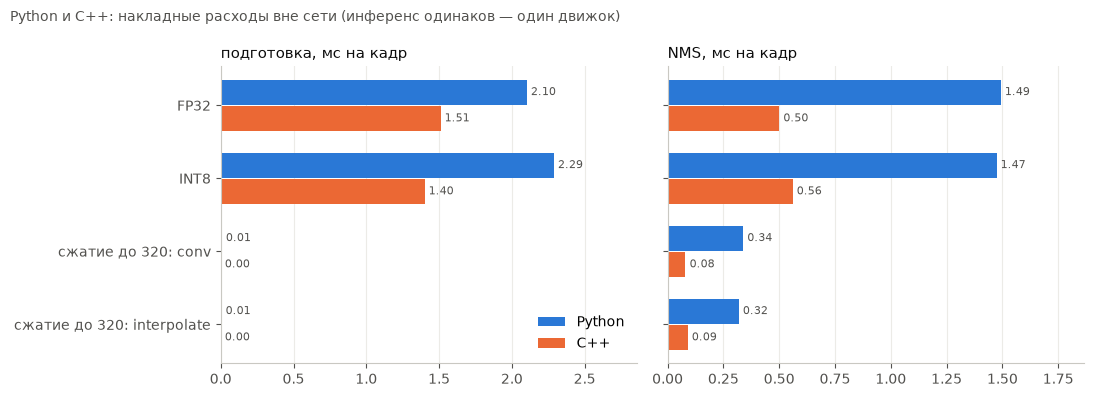

In [7]:
if cmp_rows:
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
                         "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                         "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
    labels = list(dict.fromkeys(r["Модель"] for r in cmp_rows))
    stages = [("pre", "подготовка"), ("post", "NMS")]
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.6 * len(labels) + 1.6), sharey=True)
    for ax, (key, title) in zip(axes, stages):
        y = np.arange(len(labels))
        for j, (lang, color) in enumerate([("Python", "#2a78d6"), ("C++", "#eb6834")]):
            vals = [next(r["_d"][key] for r in cmp_rows if r["Модель"] == l and r["Язык"] == lang) for l in labels]
            bars = ax.barh(y + (j - 0.5) * 0.36, vals, height=0.34, color=color, label=lang)
            ax.bar_label(bars, [f"{v:.2f}" for v in vals], padding=3, fontsize=8, color="#52514e")
        ax.set_yticks(y, labels)
        ax.set_title(f"{title}, мс на кадр", loc="left", color="#0b0b0b", fontsize=11)
        ax.grid(axis="y", visible=False)
        ax.margins(x=0.25)
    axes[0].invert_yaxis()
    axes[0].legend(frameon=False, loc="lower right")
    fig.suptitle("Python и C++: накладные расходы вне сети (инференс одинаков — один движок)", x=0.01, ha="left",
                 color="#52514e", fontsize=10)
    plt.tight_layout()
    plt.show()

## 5. Кадры из видео, размеченного программой на C++

Видео сохранены в `runs/cpp/`.

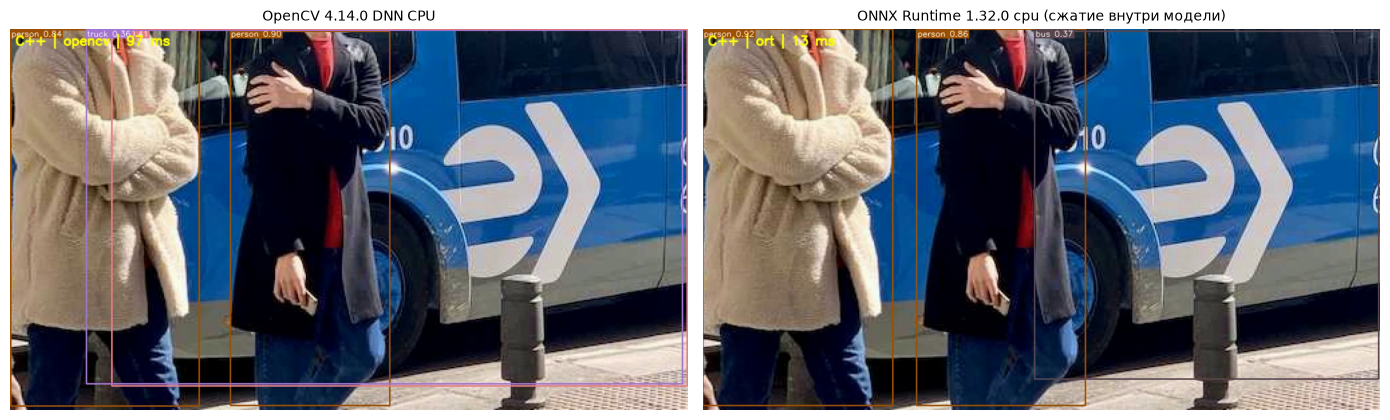

In [8]:
picked = [r for k, r in cpp_res.items() if k[1:] == ("opencv", "cpu")][:1] + [r for k, r in cpp_res.items() if "свёртк" in k[0] or "conv" in k[0]][:1]
imgs, titles = [], []
for r in picked:
    cap = cv2.VideoCapture(str(r["video"]))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT) * 0.5))
    ok, f = cap.read()
    cap.release()
    if ok:
        imgs.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        titles.append(r["backend_name"])
if imgs:
    fig, axes = plt.subplots(1, len(imgs), figsize=(7 * len(imgs), 4.2))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, titles):
        ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout()
    plt.show()

## Итоги

- Программа на C++ собирается CMake и работает с теми же ONNX-моделями, что и Python: FP32, INT8 и моделями
  со сжатием кадра внутри (F.interpolate и слой свёртки) — для последних кадр передаётся без препроцессинга.
- Инференс в C++ и Python одинаков (один движок ONNX Runtime); C++ быстрее в подготовке входа и NMS.
  На CPU, где сеть занимает ~90 % времени кадра, общая скорость почти не отличается; выигрыш C++ заметен на GPU,
  где сеть работает за единицы миллисекунд.
- На компьютере с NVIDIA ноутбук сам добавит запуски OpenCV DNN CUDA FP16 и ONNX Runtime CUDA/TensorRT.